COIL-100 Lab
Clasificación de cinco objetos del conjunto COIL-100.
Escenario A: vistas intercaladas. Escenario B: entrenamiento 0-175° y prueba 180-355°.
Este experimento NO es reconocimiento genérico de objetos ni detección en imágenes abiertas.

1. Imports y configuración

In [33]:
import os
import re
import sys
import json
import time
import shutil
import platform
import threading
import multiprocessing as mp
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torchvision

from PIL import Image
from skimage.feature import hog, local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

SEED = 42
SELECTED_OBJECTS = [43, 63, 68, 74, 75]
IMG_SIZE = 128
IMG_SIZE_SMALL = 64
BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 1e-4
N_ESTIMATORS = 100
REPS_PARALLEL = 3

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

cv2.setNumThreads(1)

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
os.chdir(WORK_DIR)

DATA_DIR = Path("data/processed")
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Directorio de trabajo:", WORK_DIR)
print("Dispositivo de entrenamiento:", "cuda" if torch.cuda.is_available() else "cpu")

Directorio de trabajo: /kaggle/working
Dispositivo de entrenamiento: cuda


2. Localizar el conjunto COIL-100 y revisar su contenido

In [37]:
POSSIBLE_ROOTS = [
    Path("/kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100"),
    Path("/kaggle/input/coil100/coil-100"),
    Path("/kaggle/input"),
    Path("coil-100"),
    Path("data"),
]

RAW_DIR = None
for candidate in POSSIBLE_ROOTS:
    if candidate.exists() and any(candidate.rglob("obj1__*.png")):
        RAW_DIR = candidate
        break

if RAW_DIR is None:
    raise FileNotFoundError(
        "No se encontró COIL-100. Revisa la ruta del dataset en Kaggle."
    )

all_raw_images = sorted(RAW_DIR.rglob("*.png"))
if not all_raw_images:
    all_raw_images = sorted(RAW_DIR.rglob("*.jpg"))

print("Dataset encontrado en:", RAW_DIR)
print("Imágenes encontradas:", len(all_raw_images))
if len(all_raw_images) == 0:
    raise RuntimeError("La carpeta encontrada no contiene imágenes PNG/JPG.")

Dataset encontrado en: /kaggle/input/datasets/jessicali9530/coil100/coil-100/coil-100
Imágenes encontradas: 7200


3. Crear una vista general de los 100 objetos (solo visualización)

Objetos encontrados: 100
Ejemplos: [100, 10, 11, 12, 13, 14, 15, 16, 17, 18]


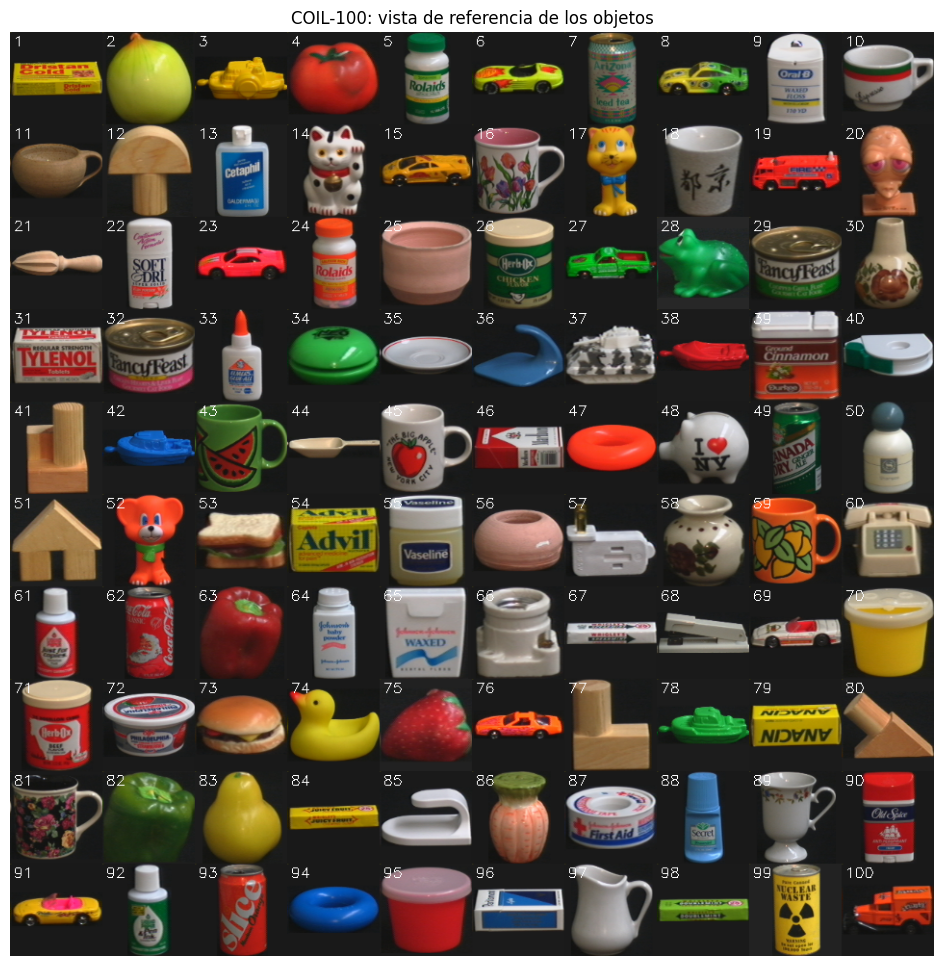

In [41]:
first_view = {}

for image_path in all_raw_images:
    parsed = get_object_and_angle(image_path)

    if parsed is None:
        continue

    obj_id, angle = parsed

    if obj_id not in first_view or angle < first_view[obj_id][0]:
        first_view[obj_id] = (angle, image_path)

print("Objetos encontrados:", len(first_view))
print("Ejemplos:", list(first_view.keys())[:10])

tiles = []

for obj_id in range(1, 101):
    if obj_id not in first_view:
        tile = np.zeros((96, 96, 3), dtype=np.uint8)
        cv2.putText(
            tile, str(obj_id), (5, 50),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7,
            (255, 255, 255), 1
        )
    else:
        tile = cv2.imread(str(first_view[obj_id][1]))

        if tile is None:
            print("No se pudo leer:", first_view[obj_id][1])
            tile = np.zeros((96, 96, 3), dtype=np.uint8)
        else:
            tile = cv2.resize(tile, (96, 96))

            cv2.putText(
                tile, str(obj_id), (3, 14),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                (255, 255, 255), 1
            )

    tiles.append(tile)

overview = np.vstack([
    np.hstack(tiles[row * 10:(row + 1) * 10])
    for row in range(10)
])

cv2.imwrite(str(FIGURES_DIR / "coil100_overview.png"), overview)

plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(overview, cv2.COLOR_BGR2RGB))
plt.title("COIL-100: vista de referencia de los objetos")
plt.axis("off")
plt.show()

4. Funciones comunes: partición de datos y extracción de características

In [42]:
def prepare_split(split_name):
    """Crea el split solicitado sin mezclar las imágenes de otros escenarios."""
    output_dir = DATA_DIR / split_name
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    return output_dir


def copy_selected_images(split_rule, split_name):
    output_dir = prepare_split(split_name)
    counts = {("train", obj): 0 for obj in SELECTED_OBJECTS}
    counts.update({("test", obj): 0 for obj in SELECTED_OBJECTS})

    for image_path in all_raw_images:
        parsed = get_object_and_angle(image_path)
        if parsed is None:
            continue
        obj_id, angle = parsed
        if obj_id not in SELECTED_OBJECTS:
            continue

        split = split_rule(angle)
        destination = output_dir / split / f"obj{obj_id:03d}"
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copy2(image_path, destination / image_path.name)
        counts[(split, obj_id)] += 1

    print(f"\\nDistribución {split_name}:")
    for key in sorted(counts):
        print(key, counts[key])

    expected_classes = {f"obj{x:03d}" for x in SELECTED_OBJECTS}
    for split in ("train", "test"):
        actual_classes = {
            p.name for p in (output_dir / split).iterdir() if p.is_dir()
        }
        if actual_classes != expected_classes:
            raise RuntimeError(
                f"Clases inesperadas en {split}: {actual_classes}; "
                f"se esperaban {expected_classes}"
            )
    return counts


def list_split(split_name, scenario):
    base = DATA_DIR / scenario / split_name
    paths, labels = [], []
    for class_dir in sorted(base.iterdir()):
        if class_dir.is_dir():
            for image_path in sorted(class_dir.glob("*.png")):
                paths.append(image_path)
                labels.append(class_dir.name)
    return paths, np.asarray(labels)


def extract_features(image_path, image_size=128):
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"No se pudo leer: {image_path}")
    image = cv2.resize(image, (image_size, image_size))

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [32], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [32], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [32], [0, 256])
    color_features = np.concatenate(
        [hist_h, hist_s, hist_v]
    ).flatten()
    color_features = color_features / (color_features.sum() + 1e-6)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        visualize=False,
    )

    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_hist, _ = np.histogram(
        lbp.ravel(), bins=np.arange(0, 11), density=True
    )
    return np.concatenate(
        [color_features, hog_features, lbp_hist]
    ).astype(np.float32)


def extract_all(paths, description):
    return np.asarray([
        extract_features(path) for path in tqdm(paths, desc=description)
    ])


def rss_mb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024 ** 2)

5. Escenario A: partición fácil con bloques de ángulos intercalados

In [43]:
def scenario_a_rule(angle):
    # Cada bloque de 20° contiene cuatro vistas (5° entre vistas).
    # Se reserva uno de cada cinco bloques para prueba.
    block = (angle // 5) // 4
    return "test" if block % 5 == 4 else "train"


copy_selected_images(scenario_a_rule, "scenario_A")

\nDistribución scenario_A:
('test', 43) 12
('test', 63) 12
('test', 68) 12
('test', 74) 12
('test', 75) 12
('train', 43) 60
('train', 63) 60
('train', 68) 60
('train', 74) 60
('train', 75) 60


{('train', 43): 60,
 ('train', 63): 60,
 ('train', 68): 60,
 ('train', 74): 60,
 ('train', 75): 60,
 ('test', 43): 12,
 ('test', 63): 12,
 ('test', 68): 12,
 ('test', 74): 12,
 ('test', 75): 12}

6. Escenario B: partición por ángulos no vistos durante el entrenamiento

In [44]:
def scenario_b_rule(angle):
    return "train" if angle < 180 else "test"


copy_selected_images(scenario_b_rule, "scenario_B")

\nDistribución scenario_B:
('test', 43) 36
('test', 63) 36
('test', 68) 36
('test', 74) 36
('test', 75) 36
('train', 43) 36
('train', 63) 36
('train', 68) 36
('train', 74) 36
('train', 75) 36


{('train', 43): 36,
 ('train', 63): 36,
 ('train', 68): 36,
 ('train', 74): 36,
 ('train', 75): 36,
 ('test', 43): 36,
 ('test', 63): 36,
 ('test', 68): 36,
 ('test', 74): 36,
 ('test', 75): 36}

7. Entrenar y evaluar Random Forest en ambos escenarios

\nRandom Forest scenario_A: train=300, test=60


Features train scenario_A:   0%|          | 0/300 [00:00<?, ?it/s]

Inferencia RF scenario_A:   0%|          | 0/60 [00:00<?, ?it/s]

              precision    recall  f1-score   support

      obj043     1.0000    1.0000    1.0000        12
      obj063     1.0000    1.0000    1.0000        12
      obj068     1.0000    1.0000    1.0000        12
      obj074     1.0000    1.0000    1.0000        12
      obj075     1.0000    1.0000    1.0000        12

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60

{
  "model": "RandomForest",
  "scenario": "scenario_A",
  "accuracy": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "feature_extraction_train_s": 2.227173895000078,
  "fit_train_s": 0.5903980349999074,
  "training_total_s": 2.8175719299999855,
  "inference_latency_mean_ms": 14.258258116664516,
  "inference_latency_p95_ms": 15.32019770000943,
  "throughput_img_s": 70.13479429378808,
  "ram_before_mb": 1807.5390625,
  "ram_after_evaluation_mb": 1807.80859375,
  "n_features": 187

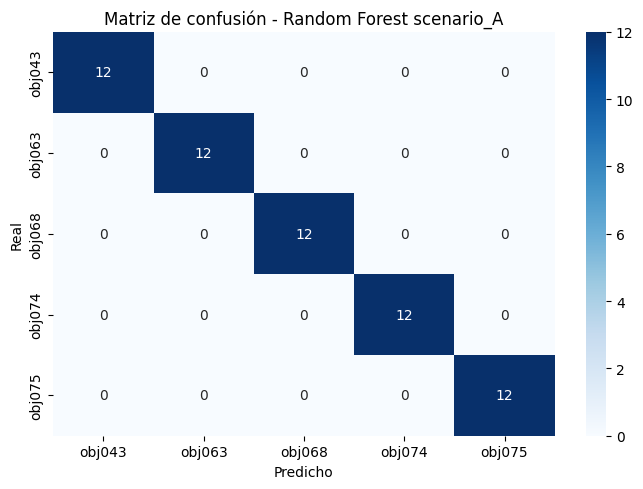

\nRandom Forest scenario_B: train=180, test=180


Features train scenario_B:   0%|          | 0/180 [00:00<?, ?it/s]

Inferencia RF scenario_B:   0%|          | 0/180 [00:00<?, ?it/s]

              precision    recall  f1-score   support

      obj043     1.0000    1.0000    1.0000        36
      obj063     0.7660    1.0000    0.8675        36
      obj068     1.0000    1.0000    1.0000        36
      obj074     1.0000    1.0000    1.0000        36
      obj075     1.0000    0.6944    0.8197        36

    accuracy                         0.9389       180
   macro avg     0.9532    0.9389    0.9374       180
weighted avg     0.9532    0.9389    0.9374       180

{
  "model": "RandomForest",
  "scenario": "scenario_B",
  "accuracy": 0.9388888888888889,
  "precision_macro": 0.9531914893617021,
  "recall_macro": 0.9388888888888889,
  "f1_macro": 0.9374284021331227,
  "feature_extraction_train_s": 1.3293187470001158,
  "fit_train_s": 0.3837974780001332,
  "training_total_s": 1.713116225000249,
  "inference_latency_mean_ms": 14.423119833342449,
  "inference_latency_p95_ms": 16.00920530007669,
  "throughput_img_s": 69.33312705953283,
  "ram_before_mb": 1808.33984375,
  

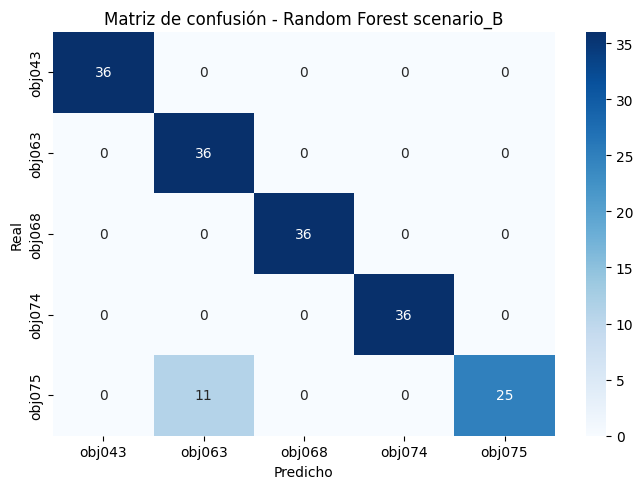

In [45]:
def evaluate_random_forest(scenario_name):
    train_paths, y_train = list_split("train", scenario_name)
    test_paths, y_test = list_split("test", scenario_name)

    print(
        f"\\nRandom Forest {scenario_name}: "
        f"train={len(train_paths)}, test={len(test_paths)}"
    )

    ram_before = rss_mb()

    t0 = time.perf_counter()
    X_train = extract_all(train_paths, f"Features train {scenario_name}")
    t_feature_train = time.perf_counter() - t0

    classifier = RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        n_jobs=1,
        random_state=SEED,
    )
    t0 = time.perf_counter()
    classifier.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0

    latencies = []
    y_pred = []
    for image_path in tqdm(test_paths, desc=f"Inferencia RF {scenario_name}"):
        start = time.perf_counter()
        features = extract_features(image_path)
        prediction = classifier.predict(features.reshape(1, -1))[0]
        latencies.append(time.perf_counter() - start)
        y_pred.append(prediction)

    y_pred = np.asarray(y_pred)
    latency_ms = np.asarray(latencies) * 1000
    labels = sorted(np.unique(y_test).tolist())

    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0
    )
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    result = {
        "model": "RandomForest",
        "scenario": scenario_name,
        "accuracy": float(accuracy),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "feature_extraction_train_s": float(t_feature_train),
        "fit_train_s": float(t_fit),
        "training_total_s": float(t_feature_train + t_fit),
        "inference_latency_mean_ms": float(latency_ms.mean()),
        "inference_latency_p95_ms": float(np.percentile(latency_ms, 95)),
        "throughput_img_s": float(len(test_paths) / np.sum(latencies)),
        "ram_before_mb": float(ram_before),
        "ram_after_evaluation_mb": float(rss_mb()),
        "n_features": int(X_train.shape[1]),
        "n_train": len(train_paths),
        "n_test": len(test_paths),
    }

    print(classification_report(
        y_test, y_pred, labels=labels, target_names=labels,
        digits=4, zero_division=0
    ))
    print(json.dumps(result, indent=2))

    with open(RESULTS_DIR / f"random_forest_{scenario_name}.json", "w") as file:
        json.dump(result, file, indent=2)
    joblib.dump(
        classifier, RESULTS_DIR / f"random_forest_{scenario_name}.joblib"
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusión - Random Forest {scenario_name}")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"cm_random_forest_{scenario_name}.png", dpi=150
    )
    plt.show()

    return result


rf_A = evaluate_random_forest("scenario_A")
rf_B = evaluate_random_forest("scenario_B")

8. MobileNetV2: preparación de datos y entrenamiento en escenario B

In [46]:
train_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo de entrenamiento MobileNetV2:", train_device)

def make_transform(image_size):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225],
        ),
    ])


def train_mobilenet(image_size, model_label):
    transform = make_transform(image_size)
    train_dataset = datasets.ImageFolder(
        DATA_DIR / "scenario_B" / "train", transform=transform
    )
    test_dataset = datasets.ImageFolder(
        DATA_DIR / "scenario_B" / "test", transform=transform
    )

    if train_dataset.classes != test_dataset.classes:
        raise RuntimeError("Las clases de train y test no coinciden.")

    generator = torch.Generator()
    generator.manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(train_device.type == "cuda"),
        generator=generator,
    )

    # Pesos preentrenados en ImageNet; se reemplaza la capa final por cinco clases.
    model = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.DEFAULT
    )
    model.classifier[1] = nn.Linear(
        model.last_channel, len(train_dataset.classes)
    )
    model = model.to(train_device)

    n_parameters = sum(parameter.numel() for parameter in model.parameters())
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    if train_device.type == "cuda":
        torch.cuda.synchronize()
    start_training = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(train_device, non_blocking=True)
            labels = labels.to(train_device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        print(
            f"{model_label} | época {epoch + 1}/{EPOCHS} | "
            f"loss={running_loss / total:.4f} | "
            f"accuracy train={100 * correct / total:.2f}%"
        )

    if train_device.type == "cuda":
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start_training

    torch.save(
        model.state_dict(),
        RESULTS_DIR / f"{model_label}_weights.pth"
    )

    training_result = {
        "model": "MobileNetV2",
        "model_label": model_label,
        "image_size": image_size,
        "training_device": str(train_device),
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "training_time_s": float(training_time),
        "n_parameters": int(n_parameters),
        "classes": train_dataset.classes,
        "n_train": len(train_dataset),
        "n_test": len(test_dataset),
    }
    with open(
        RESULTS_DIR / f"{model_label}_training.json", "w"
    ) as file:
        json.dump(training_result, file, indent=2)

    return model, test_dataset, transform, training_result

Dispositivo de entrenamiento MobileNetV2: cuda


9. Medir RAM pico mediante muestreo durante la evaluación
La métrica se denomina RAM pico muestreada: el muestreo periódico puede no capturar
picos muy breves entre dos mediciones.

In [47]:
def measure_ram_peak(function, interval_seconds=0.01):
    process = psutil.Process(os.getpid())
    peak_bytes = [process.memory_info().rss]
    running = threading.Event()
    running.set()

    def monitor():
        while running.is_set():
            try:
                current = process.memory_info().rss
                peak_bytes[0] = max(peak_bytes[0], current)
            except psutil.Error:
                pass
            time.sleep(interval_seconds)

    monitor_thread = threading.Thread(target=monitor, daemon=True)
    monitor_thread.start()
    try:
        result = function()
    finally:
        peak_bytes[0] = max(
            peak_bytes[0], process.memory_info().rss
        )
        running.clear()
        monitor_thread.join()

    return result, peak_bytes[0] / (1024 ** 2)

10. Evaluación imagen por imagen en CPU o GPU.
El tiempo de inferencia medido incluye lectura de imagen, preprocesamiento y predicción.

In [48]:
def evaluate_mobilenet_per_image(
    model, test_dataset, transform, image_size,
    training_result, device, scenario_label
):
    device = torch.device(device)
    model = model.to(device).eval()
    class_names = test_dataset.classes

    dummy = torch.randn(1, 3, image_size, image_size, device=device)
    with torch.inference_mode():
        for _ in range(5):
            model(dummy)

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)

    ram_before = rss_mb()

    def evaluate_loop():
        latencies = []
        true_labels = []
        predicted_labels = []

        with torch.inference_mode():
            for image_path, label_index in test_dataset.samples:
                start = time.perf_counter()
                with Image.open(image_path) as image_file:
                    image = image_file.convert("RGB")
                    tensor = transform(image).unsqueeze(0).to(device)

                prediction = model(tensor).argmax(dim=1).item()

                if device.type == "cuda":
                    torch.cuda.synchronize(device)

                latencies.append(time.perf_counter() - start)
                true_labels.append(class_names[label_index])
                predicted_labels.append(class_names[prediction])

        return latencies, true_labels, predicted_labels

    (latencies, y_true, y_pred), ram_peak_sampled = measure_ram_peak(
        evaluate_loop
    )

    if device.type == "cuda":
        torch.cuda.synchronize(device)
        gpu_peak_allocated = (
            torch.cuda.max_memory_allocated(device) / (1024 ** 2)
        )
    else:
        gpu_peak_allocated = None

    latency_ms = np.asarray(latencies) * 1000
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=class_names)

    result = {
        "model": "MobileNetV2",
        "scenario": scenario_label,
        "image_size": image_size,
        "accuracy": float(accuracy),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "training_device": training_result["training_device"],
        "inference_device": str(device),
        "training_time_s": training_result["training_time_s"],
        "inference_latency_mean_ms": float(latency_ms.mean()),
        "inference_latency_p95_ms": float(np.percentile(latency_ms, 95)),
        "throughput_img_s": float(len(latencies) / np.sum(latencies)),
        "ram_before_mb": float(ram_before),
        "ram_peak_sampled_mb": float(ram_peak_sampled),
        "n_parameters": training_result["n_parameters"],
        "n_test": len(test_dataset),
    }
    if gpu_peak_allocated is not None:
        result["gpu_peak_allocated_mb"] = float(gpu_peak_allocated)

    print(f"\\nResultados {scenario_label}")
    print(classification_report(
        y_true, y_pred,
        labels=class_names,
        target_names=class_names,
        digits=4,
        zero_division=0,
    ))
    print(json.dumps(result, indent=2))

    with open(RESULTS_DIR / f"{scenario_label}.json", "w") as file:
        json.dump(result, file, indent=2)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusión - {scenario_label}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"cm_{scenario_label}.png", dpi=150)
    plt.show()

    return result

11. Entrenar MobileNetV2 a 128×128 y comparar evaluación CPU/GPU

mobilenet_128_scenario_B | época 1/8 | loss=1.4252 | accuracy train=45.00%
mobilenet_128_scenario_B | época 2/8 | loss=0.8833 | accuracy train=97.22%
mobilenet_128_scenario_B | época 3/8 | loss=0.5565 | accuracy train=100.00%
mobilenet_128_scenario_B | época 4/8 | loss=0.3311 | accuracy train=100.00%
mobilenet_128_scenario_B | época 5/8 | loss=0.1874 | accuracy train=100.00%
mobilenet_128_scenario_B | época 6/8 | loss=0.1026 | accuracy train=100.00%
mobilenet_128_scenario_B | época 7/8 | loss=0.0912 | accuracy train=100.00%
mobilenet_128_scenario_B | época 8/8 | loss=0.0915 | accuracy train=100.00%
\nResultados mobilenet_128_cpu_scenario_B
              precision    recall  f1-score   support

      obj043     1.0000    1.0000    1.0000        36
      obj063     1.0000    1.0000    1.0000        36
      obj068     1.0000    1.0000    1.0000        36
      obj074     1.0000    1.0000    1.0000        36
      obj075     1.0000    1.0000    1.0000        36

    accuracy              

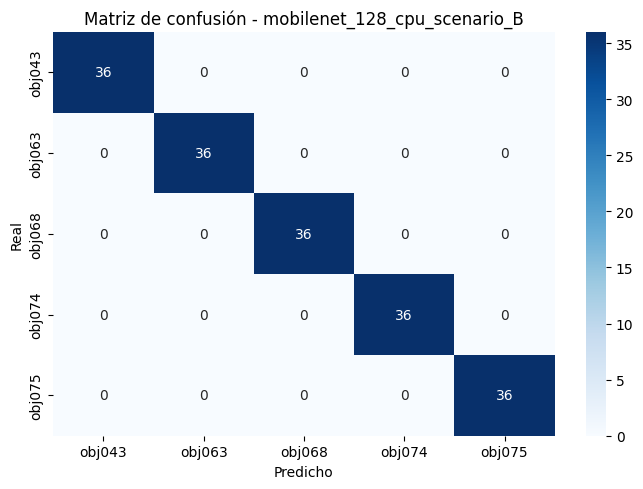

\nResultados mobilenet_128_gpu_scenario_B
              precision    recall  f1-score   support

      obj043     1.0000    1.0000    1.0000        36
      obj063     1.0000    1.0000    1.0000        36
      obj068     1.0000    1.0000    1.0000        36
      obj074     1.0000    1.0000    1.0000        36
      obj075     1.0000    1.0000    1.0000        36

    accuracy                         1.0000       180
   macro avg     1.0000    1.0000    1.0000       180
weighted avg     1.0000    1.0000    1.0000       180

{
  "model": "MobileNetV2",
  "scenario": "mobilenet_128_gpu_scenario_B",
  "image_size": 128,
  "accuracy": 1.0,
  "precision_macro": 1.0,
  "recall_macro": 1.0,
  "f1_macro": 1.0,
  "training_device": "cuda",
  "inference_device": "cuda",
  "training_time_s": 3.4769136649999837,
  "inference_latency_mean_ms": 7.259019455552283,
  "inference_latency_p95_ms": 7.787333399983254,
  "throughput_img_s": 137.7596528185524,
  "ram_before_mb": 1838.5859375,
  "ram_peak_sa

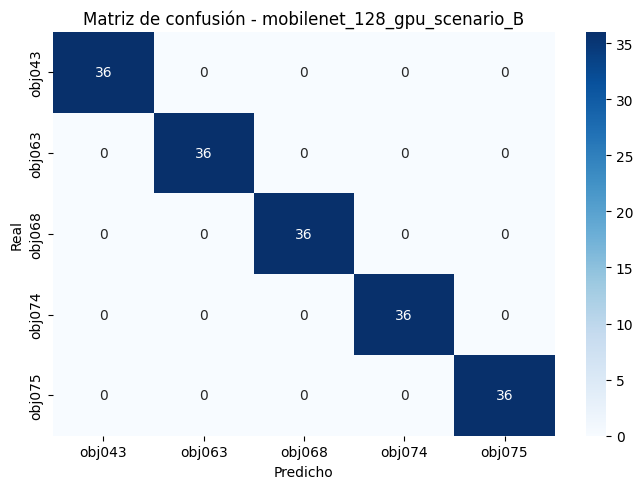

In [49]:
model128, test_ds128, transform128, training128 = train_mobilenet(
    IMG_SIZE, "mobilenet_128_scenario_B"
)

mobilenet128_cpu = evaluate_mobilenet_per_image(
    model128, test_ds128, transform128, IMG_SIZE,
    training128, torch.device("cpu"), "mobilenet_128_cpu_scenario_B"
)

if torch.cuda.is_available():
    mobilenet128_gpu = evaluate_mobilenet_per_image(
        model128, test_ds128, transform128, IMG_SIZE,
        training128, torch.device("cuda"), "mobilenet_128_gpu_scenario_B"
    )
else:
    mobilenet128_gpu = None
    print("No hay GPU disponible; se omite la evaluación GPU.")

12. MobileNetV2 a 64×64: experimento adicional de resolución

mobilenet_64_scenario_B | época 1/8 | loss=1.5418 | accuracy train=35.56%
mobilenet_64_scenario_B | época 2/8 | loss=1.1683 | accuracy train=73.33%
mobilenet_64_scenario_B | época 3/8 | loss=0.9360 | accuracy train=93.89%
mobilenet_64_scenario_B | época 4/8 | loss=0.6878 | accuracy train=98.89%
mobilenet_64_scenario_B | época 5/8 | loss=0.5086 | accuracy train=100.00%
mobilenet_64_scenario_B | época 6/8 | loss=0.3704 | accuracy train=100.00%
mobilenet_64_scenario_B | época 7/8 | loss=0.2992 | accuracy train=100.00%
mobilenet_64_scenario_B | época 8/8 | loss=0.2890 | accuracy train=100.00%
\nResultados mobilenet_64_cpu_scenario_B
              precision    recall  f1-score   support

      obj043     1.0000    0.9722    0.9859        36
      obj063     0.9474    1.0000    0.9730        36
      obj068     1.0000    1.0000    1.0000        36
      obj074     1.0000    1.0000    1.0000        36
      obj075     1.0000    0.9722    0.9859        36

    accuracy                         

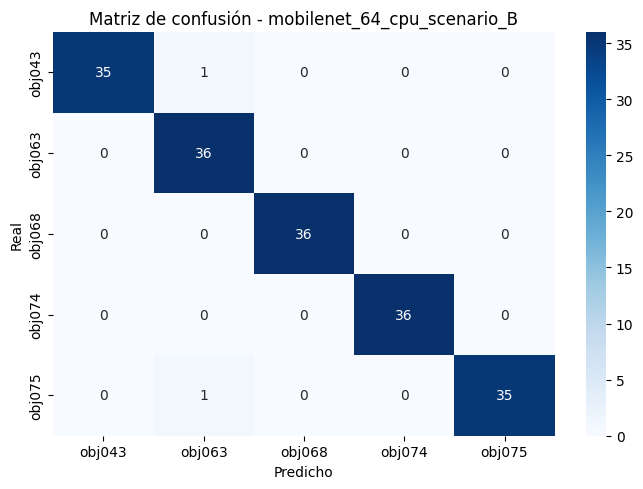

In [50]:
model64, test_ds64, transform64, training64 = train_mobilenet(
    IMG_SIZE_SMALL, "mobilenet_64_scenario_B"
)

mobilenet64_cpu = evaluate_mobilenet_per_image(
    model64, test_ds64, transform64, IMG_SIZE_SMALL,
    training64, torch.device("cpu"), "mobilenet_64_cpu_scenario_B"
)

13. Paralelización de extracción de características (escenario B)
La línea base se etiqueta como Secuencial; no se ejecuta un Pool de un proceso.

{'configuration': 'Paralelo (2 procesos)', 'processes': 2, 'time_s': 1.4797141830001692, 'speedup': 1.7526599689282747, 'efficiency': 0.8763299844641373, 'throughput_img_s': 243.29022735329073, 'same_features': True}
{'configuration': 'Paralelo (4 procesos)', 'processes': 4, 'time_s': 1.340535134999982, 'speedup': 1.9346272591354639, 'efficiency': 0.48365681478386596, 'throughput_img_s': 268.5494699846154, 'same_features': True}


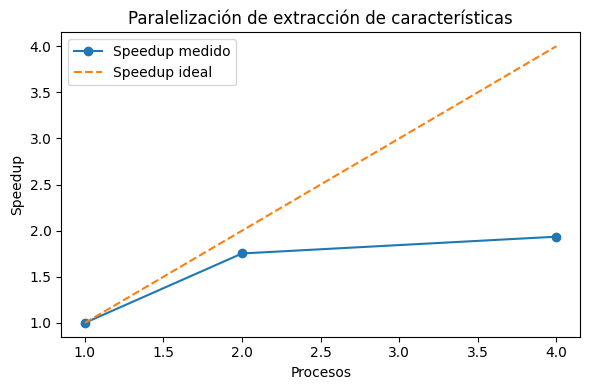

In [51]:
parallel_paths = sorted((DATA_DIR / "scenario_B").rglob("*.png"))
cpu_count = os.cpu_count() or 1
process_counts = [n for n in (2, 4) if n <= cpu_count]

def parallel_worker(image_path):
    return extract_features(image_path)

def extract_sequential(paths):
    return [parallel_worker(path) for path in paths]

def extract_parallel(paths, process_count):
    # Kaggle usa Linux; fork permite reutilizar las funciones ya definidas.
    context = mp.get_context("fork")
    with context.Pool(processes=process_count) as pool:
        return pool.map(parallel_worker, paths, chunksize=8)

# Calentamiento de caché
features_sequential = extract_sequential(parallel_paths)

sequential_times = []
for _ in range(REPS_PARALLEL):
    start = time.perf_counter()
    features_sequential = extract_sequential(parallel_paths)
    sequential_times.append(time.perf_counter() - start)

sequential_time = float(np.median(sequential_times))
parallel_rows = [{
    "configuration": "Secuencial",
    "processes": 1,
    "time_s": sequential_time,
    "speedup": 1.0,
    "efficiency": 1.0,
    "throughput_img_s": len(parallel_paths) / sequential_time,
}]

for process_count in process_counts:
    times = []
    features_parallel = None
    for _ in range(REPS_PARALLEL):
        start = time.perf_counter()
        features_parallel = extract_parallel(parallel_paths, process_count)
        times.append(time.perf_counter() - start)

    parallel_time = float(np.median(times))
    speedup = sequential_time / parallel_time
    same_features = np.allclose(
        np.asarray(features_sequential),
        np.asarray(features_parallel),
    )
    row = {
        "configuration": f"Paralelo ({process_count} procesos)",
        "processes": process_count,
        "time_s": parallel_time,
        "speedup": speedup,
        "efficiency": speedup / process_count,
        "throughput_img_s": len(parallel_paths) / parallel_time,
        "same_features": bool(same_features),
    }
    parallel_rows.append(row)
    print(row)

parallel_results = {
    "scenario": "feature_extraction_scenario_B",
    "n_images": len(parallel_paths),
    "logical_cpus": cpu_count,
    "repetitions": REPS_PARALLEL,
    "results": parallel_rows,
}
with open(RESULTS_DIR / "classic_parallel_scenario_B.json", "w") as file:
    json.dump(parallel_results, file, indent=2)

plt.figure(figsize=(6, 4))
plt.plot(
    [row["processes"] for row in parallel_rows],
    [row["speedup"] for row in parallel_rows],
    "o-",
    label="Speedup medido",
)
plt.plot(
    [row["processes"] for row in parallel_rows],
    [row["processes"] for row in parallel_rows],
    "--",
    label="Speedup ideal",
)
plt.xlabel("Procesos")
plt.ylabel("Speedup")
plt.title("Paralelización de extracción de características")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "speedup_classic_parallel_scenario_B.png", dpi=150)
plt.show()

14. Comparación adicional por tamaño de lote (batch size)
Se mide el tiempo total del recorrido del DataLoader, incluyendo carga y
transformación de imágenes, transferencia al dispositivo y predicción.

In [52]:
def evaluate_batch_size(model, dataset, device, batch_size):
    device = torch.device(device)
    model = model.to(device).eval()

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
    )

    dummy = torch.randn(
        batch_size, 3, IMG_SIZE, IMG_SIZE, device=device
    )
    with torch.inference_mode():
        model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    y_true, y_pred = [], []
    start = time.perf_counter()

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(predictions.tolist())
            y_true.extend(labels.numpy().tolist())

    if device.type == "cuda":
        torch.cuda.synchronize(device)

    total_time = time.perf_counter() - start
    return {
        "device": str(device),
        "batch_size": batch_size,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "total_time_s": float(total_time),
        "latency_ms_per_image": float(total_time / len(dataset) * 1000),
        "throughput_img_s": float(len(dataset) / total_time),
    }


batch_results = []
devices_to_test = [torch.device("cpu")]
if torch.cuda.is_available():
    devices_to_test.append(torch.device("cuda"))

for evaluation_device in devices_to_test:
    for batch_size in (1, 8, 16, 32):
        batch_result = evaluate_batch_size(
            model128, test_ds128, evaluation_device, batch_size
        )
        batch_results.append(batch_result)
        print(batch_result)

batch_df = pd.DataFrame(batch_results)
batch_df.to_csv(RESULTS_DIR / "batch_size_comparison.csv", index=False)
print(batch_df.to_string(index=False))

{'device': 'cpu', 'batch_size': 1, 'accuracy': 1.0, 'total_time_s': 3.498632395999948, 'latency_ms_per_image': 19.436846644444156, 'throughput_img_s': 51.44867468951507}
{'device': 'cpu', 'batch_size': 8, 'accuracy': 1.0, 'total_time_s': 1.37917260800009, 'latency_ms_per_image': 7.6620700444449445, 'throughput_img_s': 130.51303292704915}
{'device': 'cpu', 'batch_size': 16, 'accuracy': 1.0, 'total_time_s': 1.4925777130001734, 'latency_ms_per_image': 8.29209840555652, 'throughput_img_s': 120.59673572251651}
{'device': 'cpu', 'batch_size': 32, 'accuracy': 1.0, 'total_time_s': 1.825415993000206, 'latency_ms_per_image': 10.141199961112255, 'throughput_img_s': 98.60766022114045}
{'device': 'cuda', 'batch_size': 1, 'accuracy': 1.0, 'total_time_s': 1.5919444890000705, 'latency_ms_per_image': 8.844136050000392, 'throughput_img_s': 113.06926921369055}
{'device': 'cuda', 'batch_size': 8, 'accuracy': 1.0, 'total_time_s': 0.38299365400007446, 'latency_ms_per_image': 2.127742522222636, 'throughput_i

15. Información del entorno experimental: hardware y versiones

In [53]:
environment_info = {
    "python": sys.version,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "logical_cpus": psutil.cpu_count(logical=True),
    "physical_cpus": psutil.cpu_count(logical=False),
    "ram_total_gb": round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    ),
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "opencv": cv2.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_count": torch.cuda.device_count(),
    "gpus": [
        torch.cuda.get_device_name(index)
        for index in range(torch.cuda.device_count())
    ],
}
print(json.dumps(environment_info, indent=2))
with open(RESULTS_DIR / "environment_info.json", "w") as file:
    json.dump(environment_info, file, indent=2)

{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "logical_cpus": 4,
  "physical_cpus": 2,
  "ram_total_gb": 31.35,
  "pytorch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "numpy": "2.1.3",
  "scikit_learn": "1.6.1",
  "opencv": "4.14.0",
  "cuda_available": true,
  "cuda_version": "12.8",
  "gpu_count": 2,
  "gpus": [
    "Tesla T4",
    "Tesla T4"
  ]
}


16. Consolidar resultados de clasificación
Esta tabla contiene únicamente MobileNetV2 (sin Random Forest ni filas duplicadas
por dispositivo). La comparación CPU/GPU se presenta en la tabla de rendimiento.

In [54]:
classification_rows = [
    {
        "model": "MobileNetV2",
        "scenario": "B",
        "resolution": "128x128",
        "accuracy": mobilenet128_cpu["accuracy"],
        "precision_macro": mobilenet128_cpu["precision_macro"],
        "recall_macro": mobilenet128_cpu["recall_macro"],
        "f1_macro": mobilenet128_cpu["f1_macro"],
    },
    {
        "model": "MobileNetV2",
        "scenario": "B",
        "resolution": "64x64",
        "accuracy": mobilenet64_cpu["accuracy"],
        "precision_macro": mobilenet64_cpu["precision_macro"],
        "recall_macro": mobilenet64_cpu["recall_macro"],
        "f1_macro": mobilenet64_cpu["f1_macro"],
    },
]

classification_df = pd.DataFrame(classification_rows)
classification_df.to_csv(
    RESULTS_DIR / "classification_quality_comparison.csv", index=False
)
print(classification_df.round(4).to_string(index=False))

      model scenario resolution  accuracy  precision_macro  recall_macro  f1_macro
MobileNetV2        B    128x128    1.0000           1.0000        1.0000     1.000
MobileNetV2        B      64x64    0.9889           0.9895        0.9889     0.989


17. Tabla separada de rendimiento de MobileNetV2: CPU vs GPU

In [55]:
performance_rows = [mobilenet128_cpu]
if mobilenet128_gpu is not None:
    performance_rows.append(mobilenet128_gpu)

performance_columns = [
    "scenario",
    "training_device",
    "inference_device",
    "training_time_s",
    "inference_latency_mean_ms",
    "inference_latency_p95_ms",
    "throughput_img_s",
    "ram_peak_sampled_mb",
    "gpu_peak_allocated_mb",
]
performance_df = pd.DataFrame(performance_rows)
performance_df = performance_df[
    [column for column in performance_columns if column in performance_df.columns]
]
performance_df.to_csv(
    RESULTS_DIR / "mobilenet_cpu_gpu_performance.csv", index=False
)
print(performance_df.round(3).to_string(index=False))

                    scenario training_device inference_device  training_time_s  inference_latency_mean_ms  inference_latency_p95_ms  throughput_img_s  ram_peak_sampled_mb  gpu_peak_allocated_mb
mobilenet_128_cpu_scenario_B            cuda              cpu            3.477                     17.265                    18.422             57.92             1837.984                    NaN
mobilenet_128_gpu_scenario_B            cuda             cuda            3.477                      7.259                     7.787            137.76             1838.590                 92.337


18. Exportar MobileNetV2 128x128 a ONNX y preparar ejemplos web (opcional)

In [56]:
try:
    import onnx  # noqa: F401
    onnx_available = True
except ImportError:
    onnx_available = False

if onnx_available:
    model_web = models.mobilenet_v2(weights=None)
    model_web.classifier[1] = nn.Linear(
        model_web.last_channel, len(test_ds128.classes)
    )
    model_web.load_state_dict(
        torch.load(
            RESULTS_DIR / "mobilenet_128_scenario_B_weights.pth",
            map_location="cpu",
        )
    )
    model_web.eval()

    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    torch.onnx.export(
        model_web,
        dummy_input,
        str(RESULTS_DIR / "mobilenet_128_scenario_B.onnx"),
        input_names=["input"],
        output_names=["output"],
        dynamic_axes={
            "input": {0: "batch_size"},
            "output": {0: "batch_size"},
        },
        opset_version=17,
    )
    print("Modelo ONNX exportado.")
else:
    print("ONNX no está instalado; se omite la exportación.")

# Copia resultados, figuras y ejemplos para la demo web.
export_dir = Path("export_web")
if export_dir.exists():
    shutil.rmtree(export_dir)
(export_dir / "samples").mkdir(parents=True, exist_ok=True)
shutil.copytree(RESULTS_DIR, export_dir / "results", dirs_exist_ok=True)
shutil.copytree(FIGURES_DIR, export_dir / "figures", dirs_exist_ok=True)

for class_name in [f"obj{x:03d}" for x in SELECTED_OBJECTS]:
    source_dir = DATA_DIR / "scenario_B" / "test" / class_name
    destination_dir = export_dir / "samples" / class_name
    destination_dir.mkdir(parents=True, exist_ok=True)
    if source_dir.exists():
        for image_path in sorted(source_dir.glob("*.png"))[:4]:
            shutil.copy2(image_path, destination_dir / image_path.name)

zip_path = shutil.make_archive(
    str(WORK_DIR / "coil100_lab_export"),
    "zip",
    root_dir=export_dir,
)
print("Paquete web creado:", zip_path)

/tmp/ipykernel_49/195012284.py:21: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1123 23:02:29.863000 49 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str,

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Modelo ONNX exportado.
Paquete web creado: /kaggle/working/coil100_lab_export.zip


19. Resumen de archivos generados

In [57]:
print("Resultados guardados en:", RESULTS_DIR.resolve())
for path in sorted(RESULTS_DIR.iterdir()):
    print("-", path.name)
print("Figuras guardadas en:", FIGURES_DIR.resolve())

Resultados guardados en: /kaggle/working/results
- batch_size_comparison.csv
- classic_model.joblib
- classic_model_B.joblib
- classic_parallel_B.json
- classic_parallel_scenario_B.json
- classic_sequential_A.json
- classic_sequential_B.json
- classification_quality_comparison.csv
- cnn_mobilenet.onnx
- cnn_mobilenet.onnx.data
- cnn_mobilenet_64_B.pth
- cnn_mobilenet_B.pth
- cnn_mobilenet_cpu_64_B.json
- cnn_mobilenet_cpu_B.json
- cnn_mobilenet_gpu_B.json
- comparacion.csv
- environment_info.json
- mobilenet_128_cpu_scenario_B.json
- mobilenet_128_gpu_scenario_B.json
- mobilenet_128_scenario_B.onnx
- mobilenet_128_scenario_B.onnx.data
- mobilenet_128_scenario_B_training.json
- mobilenet_128_scenario_B_weights.pth
- mobilenet_64_cpu_scenario_B.json
- mobilenet_64_scenario_B_training.json
- mobilenet_64_scenario_B_weights.pth
- mobilenet_cpu_gpu_performance.csv
- mobilenet_training.json
- random_forest_scenario_A.joblib
- random_forest_scenario_A.json
- random_forest_scenario_B.joblib
- 